In [ ]:
# Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.model_selection import train_test_split


In [ ]:
# Dataset upload
df= pd.read_csv("songs_normalize.csv")

In [ ]:
#Print 5 rows
print("First 5 rows: ")
print(df.head())


First 5 rows: 
           artist                    song  duration_ms  explicit  year  \
0  Britney Spears  Oops!...I Did It Again       211160     False  2000   
1       blink-182    All The Small Things       167066     False  1999   
2      Faith Hill                 Breathe       250546     False  1999   
3        Bon Jovi            It's My Life       224493     False  2000   
4          *NSYNC             Bye Bye Bye       200560     False  2000   

   popularity  danceability  energy  key  loudness  mode  speechiness  \
0          77         0.751   0.834    1    -5.444     0       0.0437   
1          79         0.434   0.897    0    -4.918     1       0.0488   
2          66         0.529   0.496    7    -9.007     1       0.0290   
3          78         0.551   0.913    0    -4.063     0       0.0466   
4          65         0.614   0.928    8    -4.806     0       0.0516   

   acousticness  instrumentalness  liveness  valence    tempo         genre  
0        0.3000        

In [ ]:
print(df.tail())

              artist                                    song  duration_ms  \
1995  Jonas Brothers                                  Sucker       181026   
1996    Taylor Swift                            Cruel Summer       178426   
1997    Blanco Brown                              The Git Up       200593   
1998       Sam Smith  Dancing With A Stranger (with Normani)       171029   
1999     Post Malone                                 Circles       215280   

      explicit  year  popularity  danceability  energy  key  loudness  mode  \
1995     False  2019          79         0.842   0.734    1    -5.065     0   
1996     False  2019          78         0.552   0.702    9    -5.707     1   
1997     False  2019          69         0.847   0.678    9    -8.635     1   
1998     False  2019          75         0.741   0.520    8    -7.513     1   
1999     False  2019          85         0.695   0.762    0    -3.497     1   

      speechiness  acousticness  instrumentalness  liveness  v

In [ ]:
#Dataset size
print("Shape of dataset: ",df.shape)
print("Number of rows: ",df.shape[0])


Shape of dataset:  (2000, 18)
Number of rows:  2000


In [ ]:
#Dataset Information
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   object 
 1   song              2000 non-null   object 
 2   duration_ms       2000 non-null   int64  
 3   explicit          2000 non-null   bool   
 4   year              2000 non-null   int64  
 5   popularity        2000 non-null   int64  
 6   danceability      2000 non-null   float64
 7   energy            2000 non-null   float64
 8   key               2000 non-null   int64  
 9   loudness          2000 non-null   float64
 10  mode              2000 non-null   int64  
 11  speechiness       2000 non-null   float64
 12  acousticness      2000 non-null   float64
 13  instrumentalness  2000 non-null   float64
 14  liveness          2000 non-null   float64
 15  valence           2000 non-null   float64
 16  tempo             2000 non-null   float64


In [ ]:
#statistical Summary
df.describe()

,duration_ms,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,228748.124500,2009.49400,59.872500,0.667438,0.720366,5.378000,-5.512434,0.553500,0.103568,0.128955,0.015226,0.181216,0.551690,120.122558
std,39136.569008,5.85996,21.335577,0.140416,0.152745,3.615059,1.933482,0.497254,0.096159,0.173346,0.087771,0.140669,0.220864,26.967112
min,113000.000000,1998.00000,0.000000,0.129000,0.054900,0.000000,-20.514000,0.000000,0.023200,0.000019,0.000000,0.021500,0.038100,60.019000
25%,203580.000000,2004.00000,56.000000,0.581000,0.622000,2.000000,-6.490250,0.000000,0.039600,0.014000,0.000000,0.088100,0.386750,98.985750
50%,223279.500000,2010.00000,65.500000,0.676000,0.736000,6.000000,-5.285000,1.000000,0.059850,0.055700,0.000000,0.124000,0.557500,120.021500
75%,248133.000000,2015.00000,73.000000,0.764000,0.839000,8.000000,-4.167750,1.000000,0.129000,0.176250,0.000068,0.241000,0.730000,134.265500
max,484146.000000,2020.00000,89.000000,0.975000,0.999000,11.000000,-0.276000,1.000000,0.576000,0.976000,0.985000,0.853000,0.973000,210.851000


In [ ]:
#Types of columns
print(df.dtypes)

artist               object
song                 object
duration_ms           int64
explicit               bool
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
genre                object
dtype: object


In [ ]:
# All columns name
print(df.columns)

Index(['artist', 'song', 'duration_ms', 'explicit', 'year', 'popularity',
       'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'genre'],
      dtype='object')


In [ ]:
#statistical Summary
df.describe(include="all")

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
count,2000,2000,2000.000000,2000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000
unique,835,1879,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59
top,Rihanna,Sorry,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pop
freq,25,5,NaN,1449,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,428
mean,NaN,NaN,228748.124500,NaN,2009.49400,59.872500,0.667438,0.720366,5.378000,-5.512434,0.553500,0.103568,0.128955,0.015226,0.181216,0.551690,120.122558,NaN
std,NaN,NaN,39136.569008,NaN,5.85996,21.335577,0.140416,0.152745,3.615059,1.933482,0.497254,0.096159,0.173346,0.087771,0.140669,0.220864,26.967112,NaN
min,NaN,NaN,113000.000000,NaN,1998.00000,0.000000,0.129000,0.054900,0.000000,-20.514000,0.000000,0.023200,0.000019,0.000000,0.021500,0.038100,60.019000,NaN
25%,NaN,NaN,203580.000000,NaN,2004.00000,56.000000,0.581000,0.622000,2.000000,-6.490250,0.000000,0.039600,0.014000,0.000000,0.088100,0.386750,98.985750,NaN
50%,NaN,NaN,223279.500000,NaN,2010.00000,65.500000,0.676000,0.736000,6.000000,-5.285000,1.000000,0.059850,0.055700,0.000000,0.124000,0.557500,120.021500,NaN
75%,NaN,NaN,248133.000000,NaN,2015.00000,73.000000,0.764000,0.839000,8.000000,-4.167750,1.000000,0.129000,0.176250,0.000068,0.241000,0.730000,134.265500,NaN


In [ ]:
#Missing Values Check
df.isnull().sum().sum()

np.int64(0)

In [ ]:
#Duplicate Check
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  59


In [ ]:
#Missing Values Check
df.isnull().sum()

,0
artist,0
song,0
duration_ms,0
explicit,0
year,0
popularity,0
danceability,0
energy,0
key,0
loudness,0


In [ ]:
#Duplicate Check
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  59


In [ ]:
#Omit Duplicate Values
print("Original shape: ",df.shape)
df_drop = df.dropna()
print("Shape after removing missing values: ", df_drop.shape)

Original shape:  (2000, 18)
Shape after removing missing values:  (2000, 18)


In [ ]:
print("\nMissing values after dropna():")
print(df_drop.isnull().sum())



Missing values after dropna():
artist              0
song                0
duration_ms         0
explicit            0
year                0
popularity          0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
genre               0
dtype: int64


In [ ]:
df.isnull().sum()

,0
artist,0
song,0
duration_ms,0
explicit,0
year,0
popularity,0
danceability,0
energy,0
key,0
loudness,0


In [ ]:

Q1= df["speechiness"].quantile(0.25)
Q3= df["speechiness"].quantile(0.75)


In [ ]:
IQR= Q3-Q1
lower_limit = Q1 -1.5*IQR
upper_limit = Q3+1.5*IQR

print("Q1 =",Q1)
print("Q3=", Q3)
print("IQR", IQR)
print("Lower Limit",lower_limit)
print("Upper Limit",upper_limit)



Q1 = 0.0396
Q3= 0.129
IQR 0.08940000000000001
Lower Limit -0.0945
Upper Limit 0.2631


In [ ]:
outliers = df[
    (df["speechiness"] < lower_limit) |
    (df["speechiness"] > upper_limit)
]
print(outliers)



             artist              song  duration_ms  explicit  year  \
15          Aaliyah         Try Again       284000     False  2002   
19          Dr. Dre  The Next Episode       161506      True  1999   
30              DMX          Party Up       268866      True  1999   
44    Missy Elliott          Hot Boyz       215466      True  1998   
79         Mystikal      Shake Ya Ass       256973      True  2000   
...             ...               ...          ...       ...   ...   
1963        J. Cole      MIDDLE CHILD       213593      True  2019   
1966       Blueface          Thotiana       129264      True  2018   
1967         DaBaby              Suge       163320      True  2019   
1969  Billie Eilish     bury a friend       193143     False  2019   
1983           Sech        Otro Trago       225933      True  2019   

      popularity  danceability  energy  key  loudness  mode  speechiness  \
15            53         0.797   0.622    6    -5.642     0        0.290   
19     

In [ ]:
original_outliers = df[
    (df["speechiness"] < lower_limit) |
    (df["speechiness"] > upper_limit)
].copy()


In [ ]:
#Store original shape
original_shape = df.shape
#remove outliers
df = df[
    (df["speechiness"] >= lower_limit) &
    (df["speechiness"] <= upper_limit)
]
#store new shape
new_shape = df.shape
print("\nOriginal Outliers: ")
print(original_outliers)

print("\nDataset Shape Before Treatment: ", original_shape)
print("Dataset Shape After Treatment: ", new_shape)



Original Outliers: 
             artist              song  duration_ms  explicit  year  \
15          Aaliyah         Try Again       284000     False  2002   
19          Dr. Dre  The Next Episode       161506      True  1999   
30              DMX          Party Up       268866      True  1999   
44    Missy Elliott          Hot Boyz       215466      True  1998   
79         Mystikal      Shake Ya Ass       256973      True  2000   
...             ...               ...          ...       ...   ...   
1963        J. Cole      MIDDLE CHILD       213593      True  2019   
1966       Blueface          Thotiana       129264      True  2018   
1967         DaBaby              Suge       163320      True  2019   
1969  Billie Eilish     bury a friend       193143     False  2019   
1983           Sech        Otro Trago       225933      True  2019   

      popularity  danceability  energy  key  loudness  mode  speechiness  \
15            53         0.797   0.622    6    -5.642     0   

In [ ]:
print("\nNumber of Rows Removed: ",
      original_shape[0] - new_shape[0])

print("\nUpdated Dataset:")
print(df)



Number of Rows Removed:  189

Updated Dataset:
              artist                                    song  duration_ms  \
0     Britney Spears                  Oops!...I Did It Again       211160   
1          blink-182                    All The Small Things       167066   
2         Faith Hill                                 Breathe       250546   
3           Bon Jovi                            It's My Life       224493   
4             *NSYNC                             Bye Bye Bye       200560   
...              ...                                     ...          ...   
1995  Jonas Brothers                                  Sucker       181026   
1996    Taylor Swift                            Cruel Summer       178426   
1997    Blanco Brown                              The Git Up       200593   
1998       Sam Smith  Dancing With A Stranger (with Normani)       171029   
1999     Post Malone                                 Circles       215280   

      explicit  year  popul

In [ ]:
print(df.duplicated().sum())

54


In [ ]:
df = df.drop_duplicates()
print(df.dtypes)
print(df["artist"].unique())
print(df["genre"].unique())
print(df["song"].unique())

artist               object
song                 object
duration_ms           int64
explicit               bool
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
genre                object
dtype: object
['Britney Spears' 'blink-182' 'Faith Hill' 'Bon Jovi' '*NSYNC' 'Sisqo'
 'Eminem' 'Robbie Williams' "Destiny's Child" 'Modjo' "Gigi D'Agostino"
 'Eiffel 65' "Bomfunk MC's" 'Sting' 'Melanie C' 'Anastacia' 'Alice Deejay'
 'Linkin Park' 'Tom Jones' 'Sonique' 'M.O.P.' 'Limp Bizkit' 'Darude'
 'Da Brat' 'Moloko' 'Chicane' 'Debelah Morgan' 'Madonna' 'Ruff Endz'
 'Montell Jordan' 'Kylie Minogue' 'JAY-Z' 'LeAnn Rimes' 'Avant'
 'Enrique Iglesias' 'Toni Braxton' 'Bow Wow' 'Dr. Dre' 'Backst

In [ ]:
df = df.drop_duplicates()
print(df.dtypes)

print(df["artist"].unique())
print(df["genre"].unique())
print(df["song"].unique())

print(df["artist"].value_counts())
print(df["genre"].value_counts())
print(df["song"].value_counts())

# Label Encoding
le = LabelEncoder()
df["artist_encoded"] = le.fit_transform(df["artist"])
print(df[["artist", "artist_encoded"]].head())


artist               object
song                 object
duration_ms           int64
explicit               bool
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
genre                object
dtype: object
['Britney Spears' 'blink-182' 'Faith Hill' 'Bon Jovi' '*NSYNC' 'Sisqo'
 'Eminem' 'Robbie Williams' "Destiny's Child" 'Modjo' "Gigi D'Agostino"
 'Eiffel 65' "Bomfunk MC's" 'Sting' 'Melanie C' 'Anastacia' 'Alice Deejay'
 'Linkin Park' 'Tom Jones' 'Sonique' 'M.O.P.' 'Limp Bizkit' 'Darude'
 'Da Brat' 'Moloko' 'Chicane' 'Debelah Morgan' 'Madonna' 'Ruff Endz'
 'Montell Jordan' 'Kylie Minogue' 'JAY-Z' 'LeAnn Rimes' 'Avant'
 'Enrique Iglesias' 'Toni Braxton' 'Bow Wow' 'Dr. Dre' 'Backst

In [ ]:
# Encode the 'genre' column into numerical labels
df["genre_encoded"] = le.fit_transform(df["genre"])
print(df[["genre", "genre_encoded"]].head())

# Encode the 'song' column into numerical labels
df["song_encoded"] = le.fit_transform(df["song"])
print(df[["song", "song_encoded"]].head())

# Encode the 'artist' column into numerical labels
df["artist_encoded"] = le.fit_transform(df["artist"])
print(df[["artist", "artist_encoded"]].head())


          genre  genre_encoded
0           pop             27
1     rock, pop             51
2  pop, country             33
3   rock, metal             50
4           pop             27
                     song  song_encoded
0  Oops!...I Did It Again          1068
1    All The Small Things            59
2                 Breathe           203
3            It's My Life           746
4             Bye Bye Bye           219
           artist  artist_encoded
0  Britney Spears             110
1       blink-182             771
2      Faith Hill             235
3        Bon Jovi             103
4          *NSYNC               0


In [ ]:
df.head()

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre,artist_encoded,genre_encoded,song_encoded
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,...,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop,110,27,1068
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,...,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop",771,51,59
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,...,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country",235,33,203
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,...,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal",103,50,746
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,...,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop,0,27,219


In [ ]:
#Normalization
scaler = MinMaxScaler()
df["danceability_normalized"] = scaler.fit_transform(
     df[["danceability"]]
)
print(
     df[
         ["danceability", "danceability_normalized"]
     ].head()
)


   danceability  danceability_normalized
0         0.751                 0.735225
1         0.434                 0.360520
2         0.529                 0.472813
3         0.551                 0.498818
4         0.614                 0.573286


In [ ]:
#Normalization
scaler = MinMaxScaler()
df["acousticness_normalized"] = scaler.fit_transform(
     df[["acousticness"]]
)
print(
     df[
         ["acousticness", "acousticness_normalized"]
     ].head()
)


   acousticness  acousticness_normalized
0        0.3000                 0.307363
1        0.0103                 0.010534
2        0.1730                 0.177238
3        0.0263                 0.026928
4        0.0408                 0.041784


In [ ]:
scaler = StandardScaler()
df["acousticness_standardized"] = scaler.fit_transform(
     df[["acousticness"]]
)
print(
     df[
         ["acousticness", "acousticness_standardized"]
     ].head()
)


   acousticness  acousticness_standardized
0        0.3000                   1.003742
1        0.0103                  -0.673574
2        0.1730                   0.268433
3        0.0263                  -0.580936
4        0.0408                  -0.496984


In [ ]:
scaler = StandardScaler()
df["danceability_standardized"] = scaler.fit_transform(
     df[["danceability"]]
)
print(
     df[
         ["danceability", "danceability_standardized"]
     ].head()
)


   danceability  danceability_standardized
0         0.751                   0.606905
1         0.434                  -1.668560
2         0.529                  -0.986638
3         0.551                  -0.828720
4         0.614                  -0.376498


In [ ]:
#Numerical features select & check
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

df[features].head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.751,0.834,-5.444,0.0437,0.3000,0.000018,0.3550,0.894,95.053
1,0.434,0.897,-4.918,0.0488,0.0103,0.000000,0.6120,0.684,148.726
2,0.529,0.496,-9.007,0.0290,0.1730,0.000000,0.2510,0.278,136.859
3,0.551,0.913,-4.063,0.0466,0.0263,0.000013,0.3470,0.544,119.992
4,0.614,0.928,-4.806,0.0516,0.0408,0.001040,0.0845,0.879,172.656


In [ ]:
#Create Popularity
def popularity_category(score):
    if score >= 70:
        return "Popular"
    elif score >= 40:
        return "Moderately Popular"
    else:
        return "Not Popular"

df['popularity_category'] = df['popularity'].apply(popularity_category)

df[['popularity', 'popularity_category']].head(20)

,popularity,popularity_category
0,77,Popular
1,79,Popular
2,66,Moderately Popular
3,78,Popular
4,65,Moderately Popular
5,69,Moderately Popular
6,86,Popular
7,68,Moderately Popular
8,75,Popular
9,77,Popular


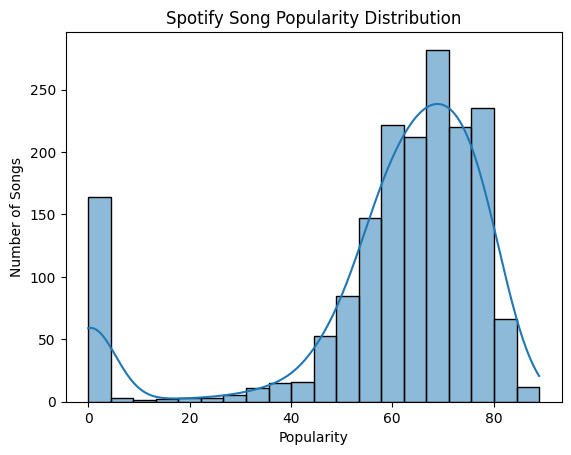

In [ ]:
#EDA Popularity Distributionplt.figure(figsize=(10,5))

sns.histplot(
    df['popularity'],
    bins=20,
    kde=True
)

plt.title("Spotify Song Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")

plt.show()

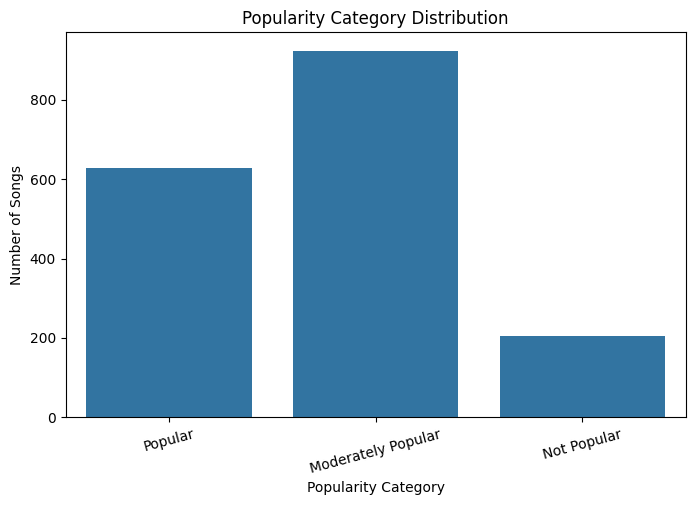

In [ ]:
#Popularity classes Visualization
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='popularity_category'
)

plt.title("Popularity Category Distribution")
plt.xlabel("Popularity Category")
plt.ylabel("Number of Songs")

plt.xticks(rotation=15)

plt.show()

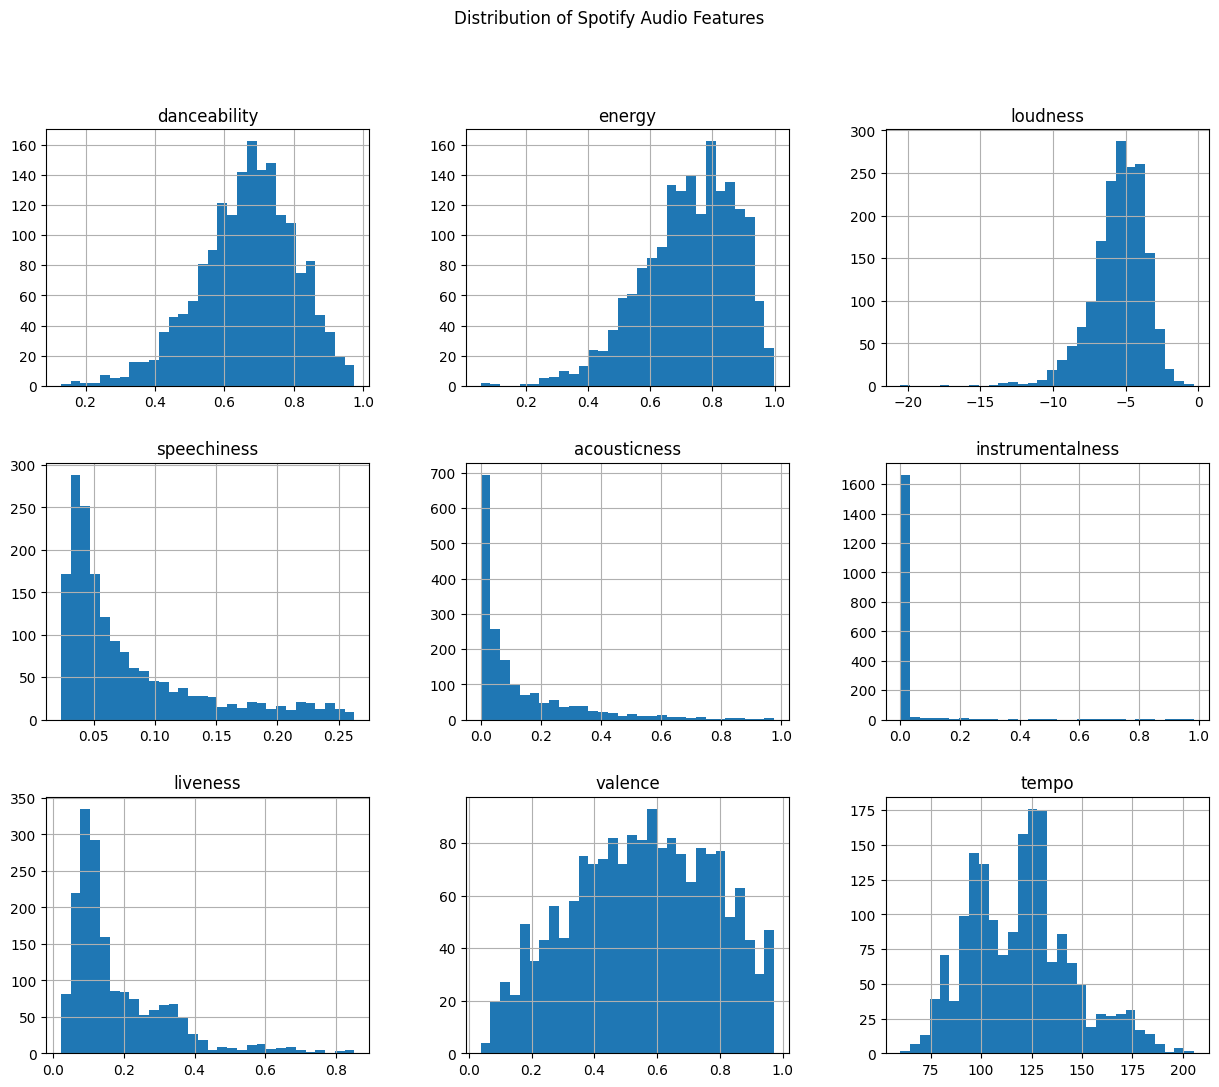

In [ ]:
#Feature Distribution
df[features].hist(
    figsize=(15,12),
    bins=30
)

plt.suptitle("Distribution of Spotify Audio Features")

plt.show()

In [ ]:
scaler = MinMaxScaler()
df_normalized = df.copy()
df_normalized[features] = scaler.fit_transform(
    df_normalized[features]
)


In [ ]:
print( df_normalized[features].head())

   danceability    energy  loudness  speechiness  acousticness  \
0      0.735225  0.825230  0.744639     0.085488      0.307363   
1      0.360520  0.891961  0.770630     0.106756      0.010534   
2      0.472813  0.467217  0.568584     0.024187      0.177238   
3      0.498818  0.908908  0.812877     0.097581      0.026928   
4      0.573286  0.924796  0.776164     0.118432      0.041784   

   instrumentalness  liveness   valence     tempo  
0          0.000018  0.401082  0.915499  0.240699  
1          0.000000  0.710162  0.690876  0.609456  
2          0.000000  0.276007  0.256605  0.527925  
3          0.000014  0.391461  0.541127  0.412041  
4          0.001056  0.075767  0.899454  0.773866  


In [ ]:
scaler = StandardScaler()
df_standardized = df.copy()
df_standardized[features] = scaler.fit_transform(
    df_standardized[features]
)
print(df_standardized[features].head())

   danceability    energy  loudness  speechiness  acousticness  \
0      0.606905  0.717632  0.004363    -0.614423      1.003742   
1     -1.668560  1.135416  0.282744    -0.525486     -0.673574   
2     -0.986638 -1.523814 -1.881324    -0.870771      0.268433   
3     -0.828720  1.241520  0.735246    -0.563851     -0.580936   
4     -0.376498  1.340993  0.342020    -0.476657     -0.496984   

   instrumentalness  liveness   valence     tempo  
0         -0.177971  1.258774  1.524436 -0.970410  
1         -0.178167  3.112127  0.587016  1.139255  
2         -0.178167  0.508779 -1.225330  0.672812  
3         -0.178018  1.201082 -0.037931  0.009840  
4         -0.166682 -0.691934  1.457477  2.079845  


In [ ]:
X = df[
    [
    "danceability",
    "acousticness",
    "valence",
    "tempo"
    ]
]
y = df["genre"]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
   X,
   y,
   test_size=0.20,
   random_state=42
)

print("Training data: ",X_train.shape)

print("Testing data: ", X_test.shape)


Training data:  (1405, 4)
Testing data:  (352, 4)


In [ ]:
print(X_train.head())

      danceability  acousticness  valence    tempo
220          0.622       0.00107    0.537  142.017
808          0.949       0.00437    0.807  117.002
610          0.819       0.01760    0.386   96.998
1395         0.645       0.29400    0.862   82.324
1812         0.791       0.03700    0.592  123.994


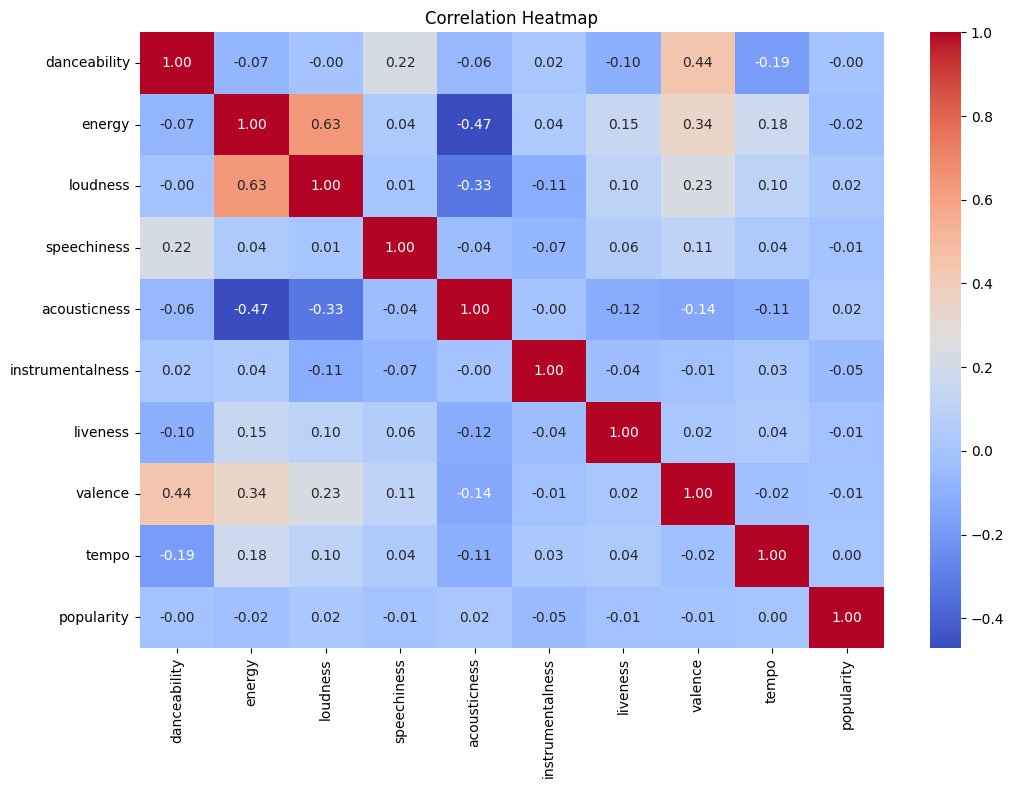

In [ ]:
#feature selection
#Correlation Heatmap
plt.figure(figsize=(12,8))

correlation = df[features + ['popularity']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

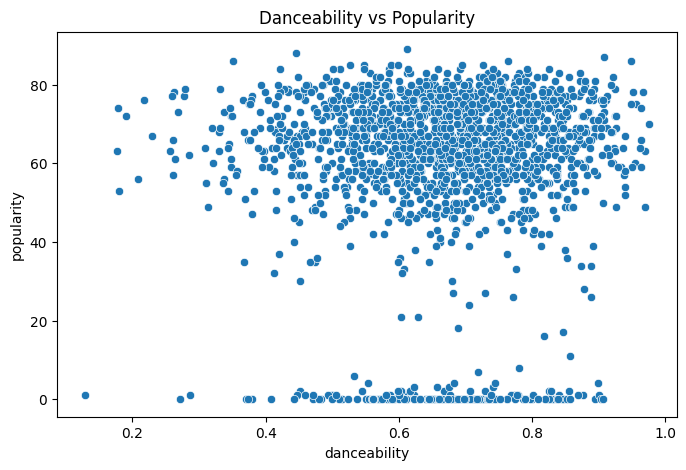

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='danceability',
    y='popularity'
)

plt.title("Danceability vs Popularity")
plt.show()

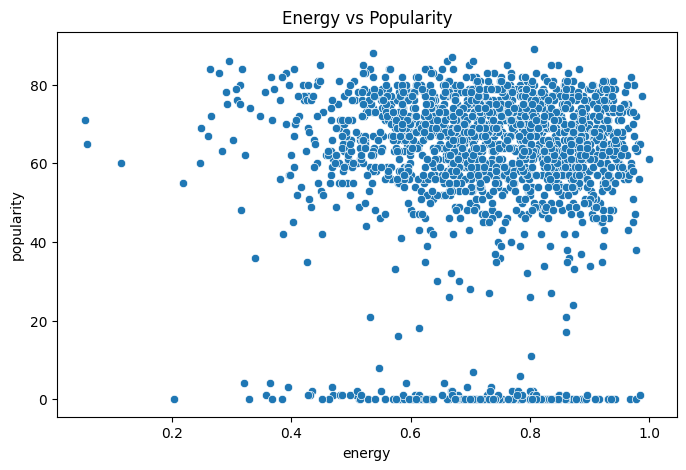

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='energy',
    y='popularity'
)

plt.title("Energy vs Popularity")
plt.show()

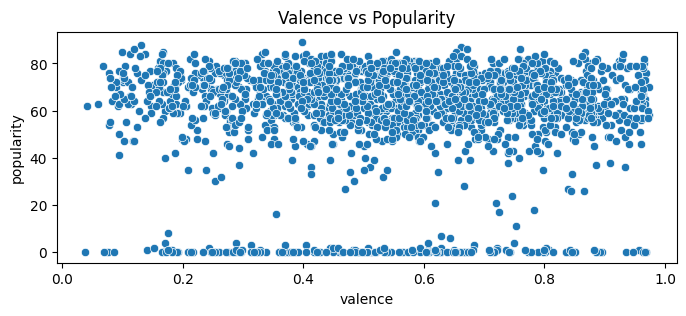

In [ ]:
plt.figure(figsize=(8,3))

sns.scatterplot(
    data=df,
    x='valence',
    y='popularity'
)

plt.title("Valence vs Popularity")
plt.show()

In [ ]:
X = df[features]

y = df['popularity_category']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1757, 9)
y shape: (1757,)


In [ ]:
#Train-Test-split & checking
X_train, X_test, y_train, y_test = train_test_split(
   X,
   y,
   test_size=0.20,
   random_state=42

)

print("Training data: ",X_train.shape)

print("Testing data: ", X_test.shape)


Training data:  (1405, 9)
Testing data:  (352, 9)


In [ ]:
#Feature Scaling using Standard Scaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (1405, 9)
Scaled testing data: (352, 9)


In [ ]:
#Logistic Regression & Prediction
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("===== Logistic Regression =====")
print("Model trained successfully!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Predictions generated:", len(y_pred_logistic))
print("First 10 predictions:")
print(y_pred_logistic[:10])

===== Logistic Regression =====
Model trained successfully!
Training data shape: (1405, 9)
Testing data shape: (352, 9)
Predictions generated: 352
First 10 predictions:
['Moderately Popular' 'Moderately Popular' 'Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular']


In [ ]:
# Decision Tree & Prediction
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)
decision_tree.fit(X_train, y_train)
y_pred_tree = decision_tree.predict(X_test)
print("===== Decision Tree =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_tree))
print("First 10 predictions:")
print(y_pred_tree[:10])

===== Decision Tree =====
Model trained successfully!
Training data shape: (1405, 9)
Testing data shape: (352, 9)
Predictions generated: 352
First 10 predictions:
['Popular' 'Popular' 'Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular']


In [ ]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

print("===== Random Forest =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_rf))
print("First 10 predictions:")
print(y_pred_rf[:10])

===== Random Forest =====
Model trained successfully!
Training data shape: (1405, 9)
Testing data shape: (352, 9)
Predictions generated: 352
First 10 predictions:
['Popular' 'Moderately Popular' 'Popular' 'Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular']


In [ ]:
# Model Evaluation Function
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    print("=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    return accuracy, precision, recall, f1

In [ ]:
#Evaluate Logistic Regression
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.5227
Precision: 0.4521
Recall   : 0.5227
F1 Score : 0.4309

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.53      0.90      0.67       182
       Not Popular       0.00      0.00      0.00        38
           Popular       0.48      0.15      0.23       132

          accuracy                           0.52       352
         macro avg       0.34      0.35      0.30       352
      weighted avg       0.45      0.52      0.43       352



In [ ]:
# Evaluate Decision Tree
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.5227
Precision: 0.4521
Recall   : 0.5227
F1 Score : 0.4309

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.53      0.90      0.67       182
       Not Popular       0.00      0.00      0.00        38
           Popular       0.48      0.15      0.23       132

          accuracy                           0.52       352
         macro avg       0.34      0.35      0.30       352
      weighted avg       0.45      0.52      0.43       352



In [ ]:
#Evaluate Random Forest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf
)

Random Forest
Accuracy : 0.5227
Precision: 0.5597
Recall   : 0.5227
F1 Score : 0.4649

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.54      0.82      0.65       182
       Not Popular       1.00      0.03      0.05        38
           Popular       0.47      0.26      0.33       132

          accuracy                           0.52       352
         macro avg       0.67      0.37      0.34       352
      weighted avg       0.56      0.52      0.46       352



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Function to train and evaluate a model
def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    return [acc, prec, rec, f1]

# 1. Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
logistic_results = evaluate_model(lr_model, X_train, X_test, y_train, y_test)

# 2. Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
tree_results = evaluate_model(dt_model, X_train, X_test, y_train, y_test)

# 3. Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_results = evaluate_model(rf_model, X_train, X_test, y_train, y_test)

print("All models trained and evaluated successfully!")

All models trained and evaluated successfully!


In [ ]:
# Model Comparison
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'Accuracy': [
        logistic_results[0],
        tree_results[0],
        rf_results[0]
    ],

    'Precision': [
        logistic_results[1],
        tree_results[1],
        rf_results[1]
    ],

    'Recall': [
        logistic_results[2],
        tree_results[2],
        rf_results[2]
    ],

    'F1 Score': [
        logistic_results[3],
        tree_results[3],
        rf_results[3]
    ]
})

print("===== Model Performance Comparison =====")
display(results)

===== Model Performance Comparison =====


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.517045,0.443131,0.517045,0.418754
1,Decision Tree,0.460227,0.462949,0.460227,0.461062
2,Random Forest,0.534091,0.505173,0.534091,0.476175


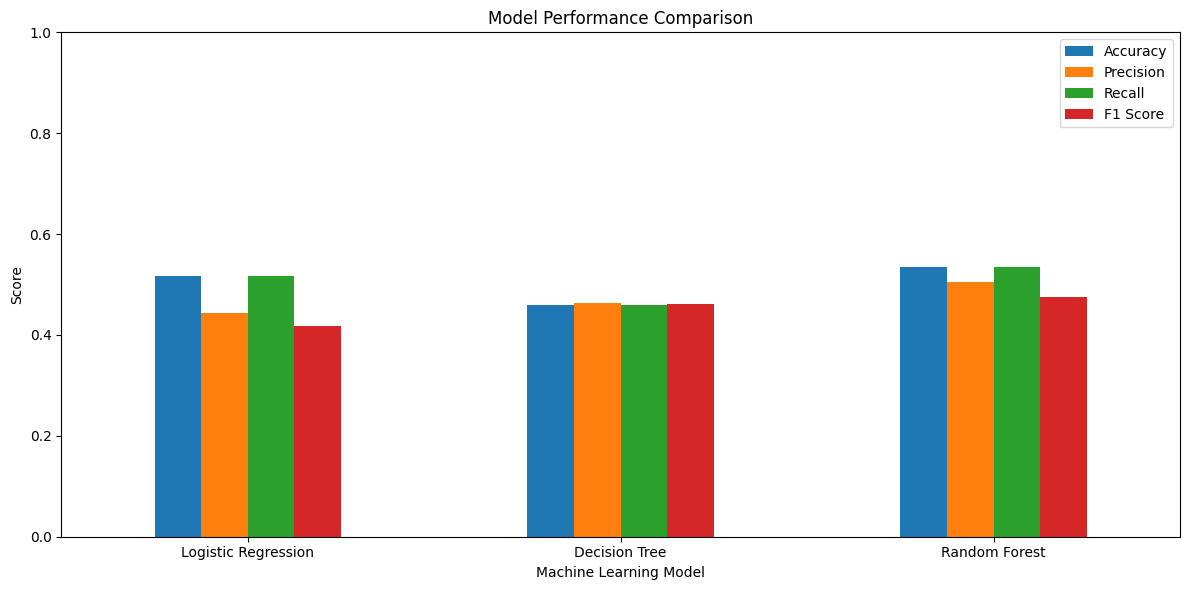

In [ ]:
# Model Comparison Graph
import matplotlib.pyplot as plt

results.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

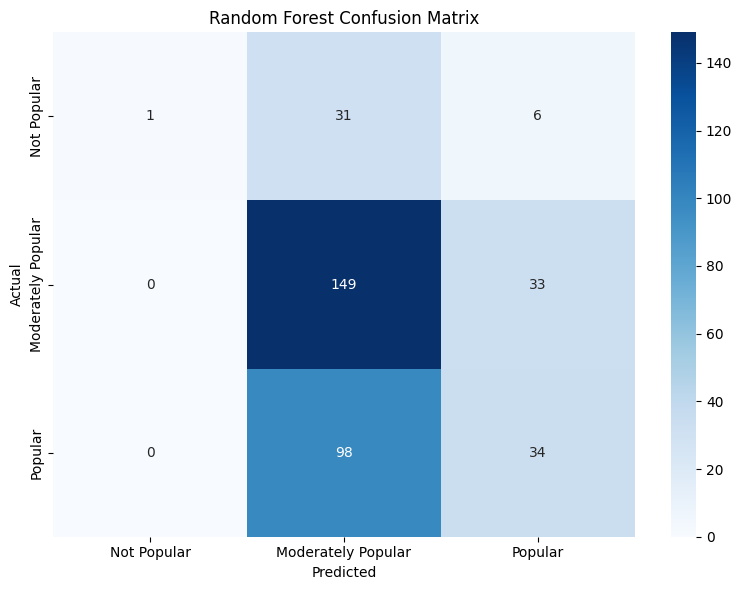

In [ ]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ],
    yticklabels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
#Feature Independence
#1. Calculate Feature Importance
import pandas as pd

importance = pd.DataFrame({
    'Feature': features,
    'Importance': random_forest.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("===== Feature Importance =====")
display(importance)

===== Feature Importance =====


,Feature,Importance
1,energy,0.124000
7,valence,0.123141
3,speechiness,0.119662
6,liveness,0.116728
2,loudness,0.114978
4,acousticness,0.113967
0,danceability,0.109231
8,tempo,0.108423
5,instrumentalness,0.069870


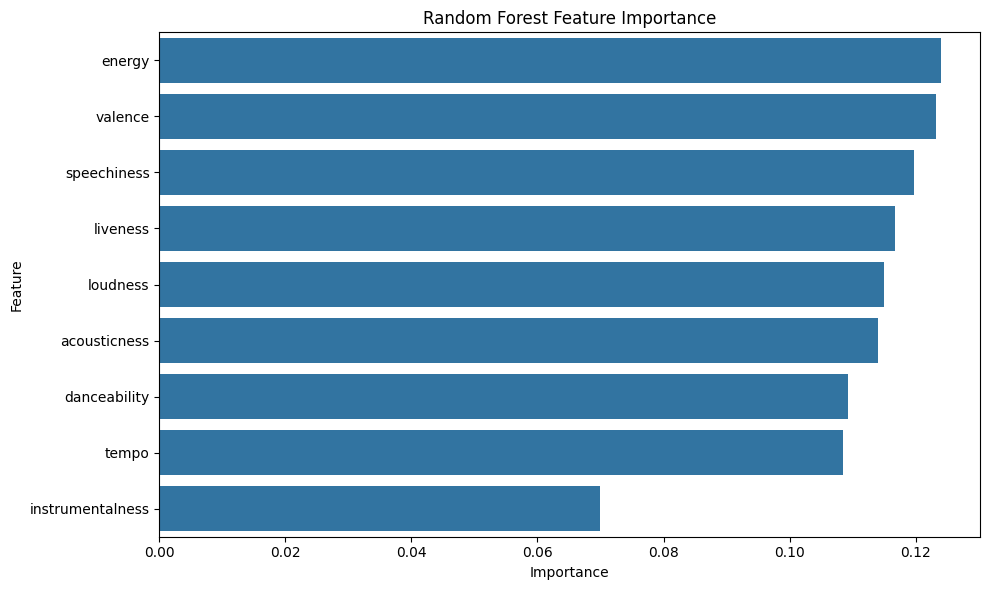

In [ ]:
#2. Feature Importance Graph
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
#Create New Song
new_song = pd.DataFrame({
    'danceability': [0.80],
    'energy': [0.75],
    'loudness': [-5.0],
    'speechiness': [0.05],
    'acousticness': [0.10],
    'instrumentalness': [0.01],
    'liveness': [0.10],
    'valence': [0.80],
    'tempo': [120]
})

print("===== New Song Features =====")
display(new_song)

===== New Song Features =====


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.8,0.75,-5.0,0.05,0.1,0.01,0.1,0.8,120


In [ ]:
# Prediction Popularity
prediction = random_forest.predict(new_song)

print("===== Prediction Result =====")
print("Predicted Popularity Category:", prediction[0])

===== Prediction Result =====
Predicted Popularity Category: Moderately Popular


In [ ]:
# Prediction Probability
probability = random_forest.predict_proba(new_song)

print("===== Prediction Probabilities =====")

for category, prob in zip(
    random_forest.classes_,
    probability[0]
):
    print(f"{category}: {prob * 100:.2f}%")

===== Prediction Probabilities =====
Moderately Popular: 59.50%
Not Popular: 14.50%
Popular: 26.00%
